# DASC8412 Assignment 2, Question 7: code generated by Gemini

**Student:** Cameron Totham (ST10301625)  
**Model:** Gemini (Google, Auto mode)  
**Date generated:** 14 October 2026  
**Shared conversation:** https://share.gemini.google/BXa0YQKnGrry  
**Dataset:** School_Data_CSV.csv from Combrink, H., Carr, E., de Wet, K., Marivate, V. and Rosman, B. 2023. *South Africa Education Data and Visualisations*. University of the Free State. https://doi.org/10.38140/ufs.22081058.v4 (the CSV must be in the same folder as this notebook).

## Prompt (identical for both models; the CSV was attached)

> Attached above is a CSV file called School_Data_CSV.csv containing South African school data. Its contains columns such as, emisno, centername, institution_name, centreno, quintile, ward_id, street_address, new_long, new_lat.
>
> Write Python code that loads this file and creates the following three visualisations:
>
> a) A line plot showing how the number of schools per quintile changes across wards.
> b) A scatter plot showing the geographic locations of schools using new_lat and new_long.
> c) A histogram showing the distribution of schools by quintile.
>
> Provide the complete code.

## Note on the code

The code cells below are reproduced exactly as Gemini generated them. They have only been split into cells at the script's own section comments so that each chart appears under the code that produced it. Gemini first ran five exploratory cells on the attached file (Part 1) and then returned its final script (Part 2). Exploratory cell 1 reads the file as UTF-8 and raises a UnicodeDecodeError; this error is kept in the output because it is what led Gemini to test other encodings in cell 2.

## Part 1: exploratory code Gemini ran on the attached file before answering

In [1]:
import pandas as pd
import os

print(os.listdir('.'))
if os.path.exists('School_Data_CSV.csv'):
    df = pd.read_csv('School_Data_CSV.csv')
    print(df.head(2))
    print(df.columns)
else:
    print("File not found")

['ChatGPT_Generated_Code.ipynb', 'School_Data_CSV.csv']


UnicodeDecodeError: 'utf-8' codec can't decode byte 0xeb in position 7896: invalid continuation byte

In [2]:
import pandas as pd
for enc in ['utf-8', 'latin1', 'cp1252', 'iso-8859-1']:
    try:
        df = pd.read_csv('School_Data_CSV.csv', encoding=enc)
        print(f"Successfully read with encoding: {enc}")
        print(df.head(2))
        print(df.columns)
        break
    except Exception as e:
        print(f"Failed with {enc}: {e}")

Failed with utf-8: 'utf-8' codec can't decode byte 0xe9 in position 1: invalid continuation byte


Successfully read with encoding: latin1
      emisno                      centername           institution_name  \
0  200100005  ABERDEEN SECONDARY SCHOOL (20)  ABERDEEN SECONDARY SCHOOL   
1  200100012              ADELAIDE GYMNASIUM         ADELAIDE GYMNASIUM   

  centreno quintile   ward_id                         street_address  \
0  4201001        3  21001001  10 PARLIAMENT STREET,  ABERDEEN, 6270   
1  4171044        4  21208001           WELSH STREET, ADELAIDE, 5760   

   new_long   new_lat  
0  24.06183 -32.47385  
1  26.29476 -32.71036  
Index(['emisno', 'centername', 'institution_name', 'centreno', 'quintile',
       'ward_id', 'street_address', 'new_long', 'new_lat'],
      dtype='str')


~\AppData\Local\Temp\ipykernel_21280\3213269926.py:4: DtypeWarning: Columns (0: emisno, 1: new_long) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('School_Data_CSV.csv', encoding=enc)


In [3]:
import pandas as pd
df = pd.read_csv('School_Data_CSV.csv', encoding='latin1', low_memory=False)
print(df.info())
print(df[['quintile', 'ward_id', 'new_lat', 'new_long']].head())
print(df['quintile'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 199853 entries, 0 to 199852
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   emisno            199853 non-null  str    
 1   centername        193922 non-null  str    
 2   institution_name  133926 non-null  str    
 3   centreno          199823 non-null  str    
 4   quintile          197040 non-null  str    
 5   ward_id           199071 non-null  str    
 6   street_address    193150 non-null  str    
 7   new_long          167741 non-null  str    
 8   new_lat           84107 non-null   float64
dtypes: float64(1), str(8)
memory usage: 13.7 MB
None
         quintile   ward_id   new_lat  new_long
0               3  21001001 -32.47385  24.06183
1               4  21208001 -32.71036  26.29476
2               3  21002002 -32.74592  25.60073
3  NOT APPLICABLE  29500009 -33.91924  25.53563
4               5  29300007 -33.94147  25.57181
quintile
1                     

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('School_Data_CSV.csv', encoding='latin1', low_memory=False)

# Clean / inspect data for plotting
print("Unique quintiles raw:", df['quintile'].unique())

Unique quintiles raw: <StringArray>
[                                                '3',
                                                 '4',
                                    'NOT APPLICABLE',
                                                 '5',
                                                 '2',
                                                'Q3',
                                                 '1',
                                               'NQ2',
                                                 '.',
                                                 nan,
                                                'Q5',
                                               'NQ5',
                                               'NQ3',
                                               'NQ4',
                                               'NQ1',
                                                'Q4',
                                                'Q2',
                                              

In [5]:
print("Number of unique wards:", df['ward_id'].nunique())
print("Number of unique valid quintiles:", df['quintile'].dropna().unique())

Number of unique wards: 4857
Number of unique valid quintiles: <StringArray>
[                                                '3',
                                                 '4',
                                    'NOT APPLICABLE',
                                                 '5',
                                                 '2',
                                                'Q3',
                                                 '1',
                                               'NQ2',
                                                 '.',
                                                'Q5',
                                               'NQ5',
                                               'NQ3',
                                               'NQ4',
                                               'NQ1',
                                                'Q4',
                                                'Q2',
                                                'Q1',
     

## Part 2: Gemini's final script

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset (using latin1 encoding to handle special characters)
file_path = "School_Data_CSV.csv"
df = pd.read_csv(file_path, encoding="latin1", low_memory=False)

# --- Data Cleaning ---

# Clean coordinates: Convert to numeric, dropping invalid/missing values
df["new_lat"] = pd.to_numeric(df["new_lat"], errors="coerce")
df["new_long"] = pd.to_numeric(df["new_long"], errors="coerce")

# Clean quintile column: standardize string values and filter out non-standard entries
# We map standard numerical and prefix variants (e.g., '1', 'Q1', 'NQ1') to clean categories
def clean_quintile(val):
    if pd.isna(val):
        return None
    val_str = str(val).strip().upper()
    if val_str in ["1", "Q1", "NQ1"]:
        return "Quintile 1"
    elif val_str in ["2", "Q2", "NQ2"]:
        return "Quintile 2"
    elif val_str in ["3", "Q3", "NQ3"]:
        return "Quintile 3"
    elif val_str in ["4", "Q4", "NQ4"]:
        return "Quintile 4"
    elif val_str in ["5", "Q5", "NQ5"]:
        return "Quintile 5"
    return None

df["clean_quintile"] = df["quintile"].apply(clean_quintile)

# Set visual style
sns.set_theme(style="whitegrid")

<Figure size 1400x600 with 0 Axes>

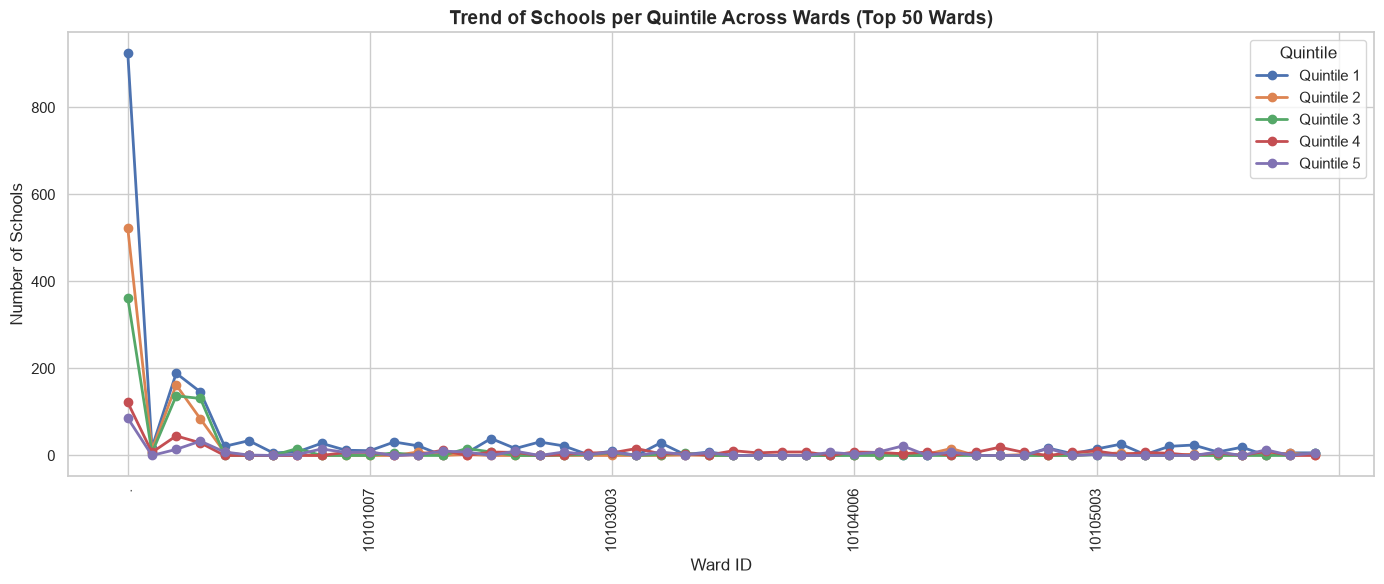

In [7]:
# ==========================================
# a) Line Plot: Number of schools per quintile across wards
# ==========================================
plt.figure(figsize=(14, 6))

# Group by ward_id and clean_quintile, then pivot to get quintiles as columns
ward_quintile_counts = (
    df.dropna(subset=["ward_id", "clean_quintile"])
    .groupby(["ward_id", "clean_quintile"])
    .size()
    .unstack(fill_value=0)
)

# For clarity in a line plot, we can sort wards by total schools or take a representative sample/head if there are thousands
ward_quintile_counts = ward_quintile_counts.sort_index()

# Plotting top 50 wards for readability (or plot all if desired)
ward_quintile_counts.head(50).plot(kind="line", marker="o", linewidth=2, figsize=(14, 6))
plt.title("Trend of Schools per Quintile Across Wards (Top 50 Wards)", fontsize=14, fontweight="bold")
plt.xlabel("Ward ID", fontsize=12)
plt.ylabel("Number of Schools", fontsize=12)
plt.xticks(rotation=90)
plt.legend(title="Quintile")
plt.tight_layout()
plt.show()

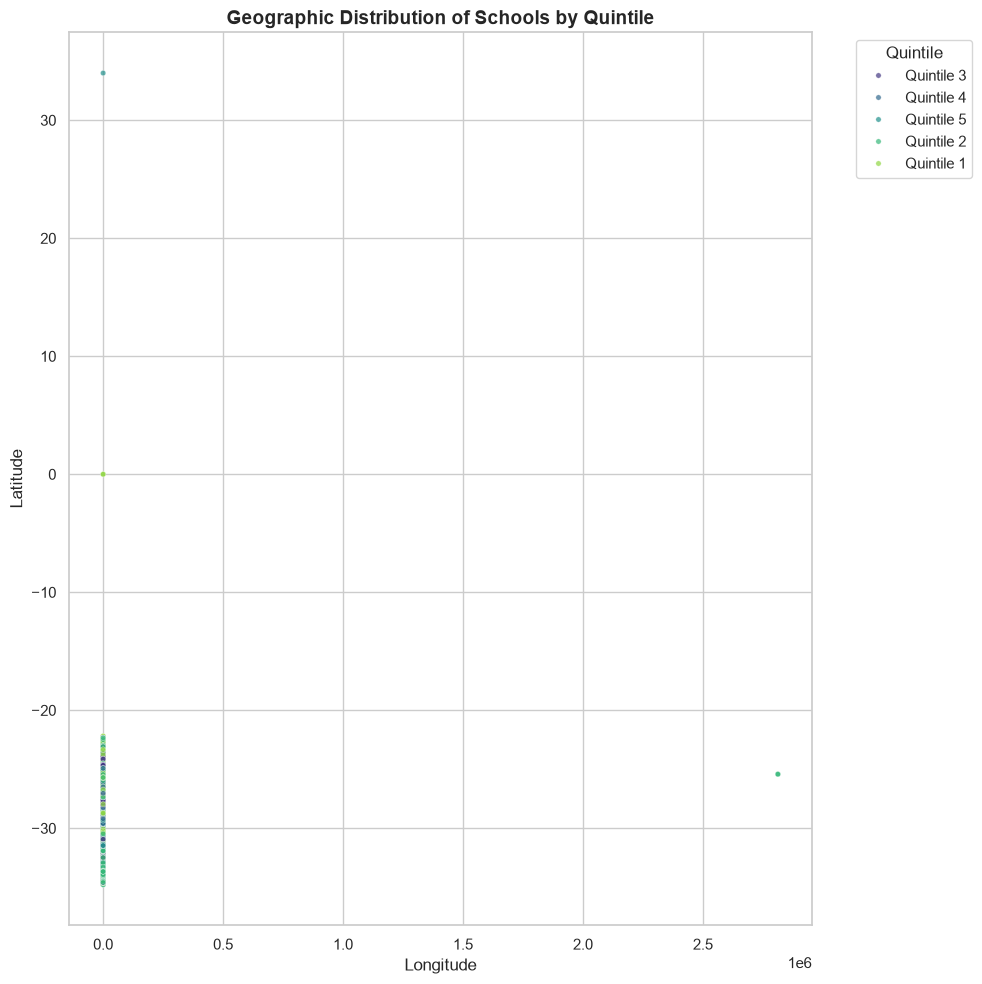

In [8]:
# ==========================================
# b) Scatter Plot: Geographic locations (new_lat & new_long)
# ==========================================
plt.figure(figsize=(10, 10))
geo_df = df.dropna(subset=["new_lat", "new_long"])

sns.scatterplot(
    data=geo_df,
    x="new_long",
    y="new_lat",
    hue="clean_quintile",
    palette="viridis",
    s=15,
    alpha=0.7
)
plt.title("Geographic Distribution of Schools by Quintile", fontsize=14, fontweight="bold")
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.legend(title="Quintile", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

~\AppData\Local\Temp\ipykernel_21280\2876076932.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


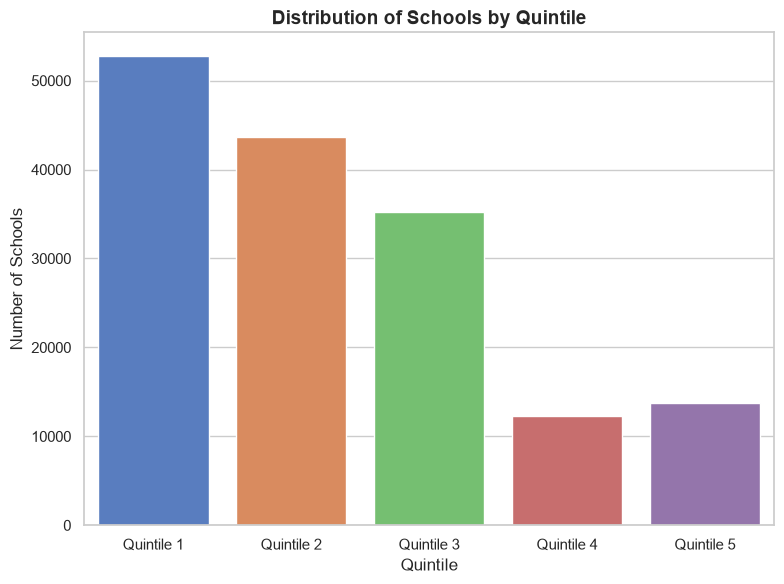

In [9]:
# ==========================================
# c) Histogram: Distribution of schools by quintile
# ==========================================
plt.figure(figsize=(8, 6))

sns.countplot(
    data=df.dropna(subset=["clean_quintile"]),
    x="clean_quintile",
    order=["Quintile 1", "Quintile 2", "Quintile 3", "Quintile 4", "Quintile 5"],
    palette="muted"
)
plt.title("Distribution of Schools by Quintile", fontsize=14, fontweight="bold")
plt.xlabel("Quintile", fontsize=12)
plt.ylabel("Number of Schools", fontsize=12)
plt.tight_layout()
plt.show()